In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

# elif "augustiner" in hostname: 
#     DATA_DIR = "/home/franzihe/Data/"
#     FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)
# sys.path.append(os.path.join(UTILS_DIR, 'pymascdb'))
os.chdir(os.path.join(UTILS_DIR, 'pymascdb'))

# # make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
from imports_mascdb import (masc, np, pd, cm, xr, glob, set_context, plt, mdates, time, datetime)

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
masc_in = os.path.join(INPUT_DATA_DIR, 'MASC_DB')
### Create MASC_DB instance 
mascdb = masc.MASC_DB(dir_path=masc_in)

In [6]:
campaign23 = mascdb.select_campaign('Norway-2023')


In [13]:
cam1 = campaign23.cam1.copy()
# 2) ensure datetime column is datetime dtype
cam1['datetime'] = pd.to_datetime(cam1['datetime'])
# 3) boolean mask for the desired interval
mask = (
    (cam1['datetime'] >= "2023-03-08 17:00") &
    (cam1['datetime'] <= "2023-03-08 20:00")
)

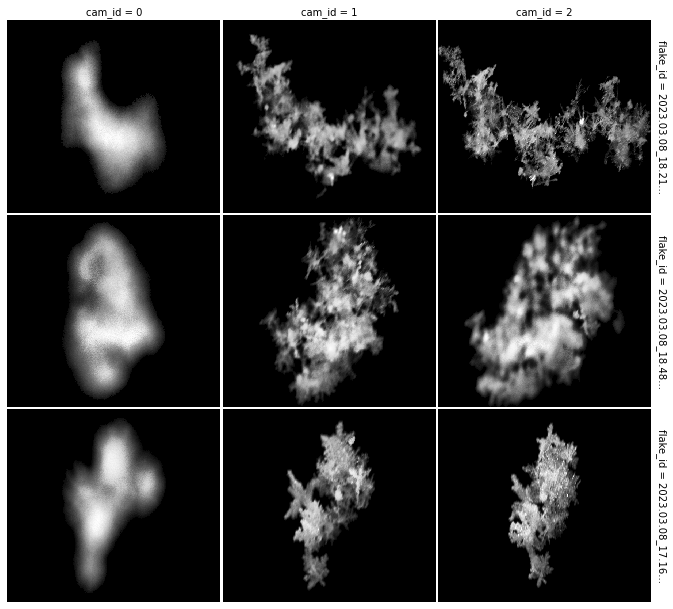

In [53]:
if cam1.index.name == "flake_id":
    flake_ids = cam1.index[mask].tolist()
elif 'flake_id' in cam1.columns:
    flake_ids = cam1.loc[mask, 'flake_id'].tolist()
else:
    raise RuntimeError("Can't find flake_id as index or column in cam1")

if len(flake_ids) == 0:
    print("No flakes found in that time window.")
else:
    # 5) subset the MASC_DB using sel
    subset_db = campaign23.sel(flake_ids=flake_ids)   # returns a MASC_DB instance. 

    # 6) then use your arrange / plot pipeline on the subset
    largeD = subset_db.arrange('cam1.Dmax', decreasing=True)   
    largeD.plot_triplets(n_triplets=3)                         # plot_triplets 

# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-09.png'), format='png', bbox_inches='tight', dpi=300) #transparent=True,

In [61]:
	
# Filter on quality
print("Number of flakes:", len(subset_db))
print("Filtering on average triplet image quality > 9.")
idx = subset_db.triplet["flake_quality_xhi"] > 9.0 # Average quality ind (on the three cams)| "xi" in Praz et 
subset_db = subset_db.isel(idx)

print("Number of flakes:", len(subset_db))
# # Filter on classification probability
# print("Filtering on average triplet hydrometeor classification probabiliy > 0.9")
# idx = subset_db.triplet["snowflake_class_prob"] > 0.9 # classification probability
# subset_db = subset_db.isel(idx)

# print("Number of flakes:", len(subset_db))

Number of flakes: 60
Filtering on average triplet image quality > 9.
Number of flakes: 60


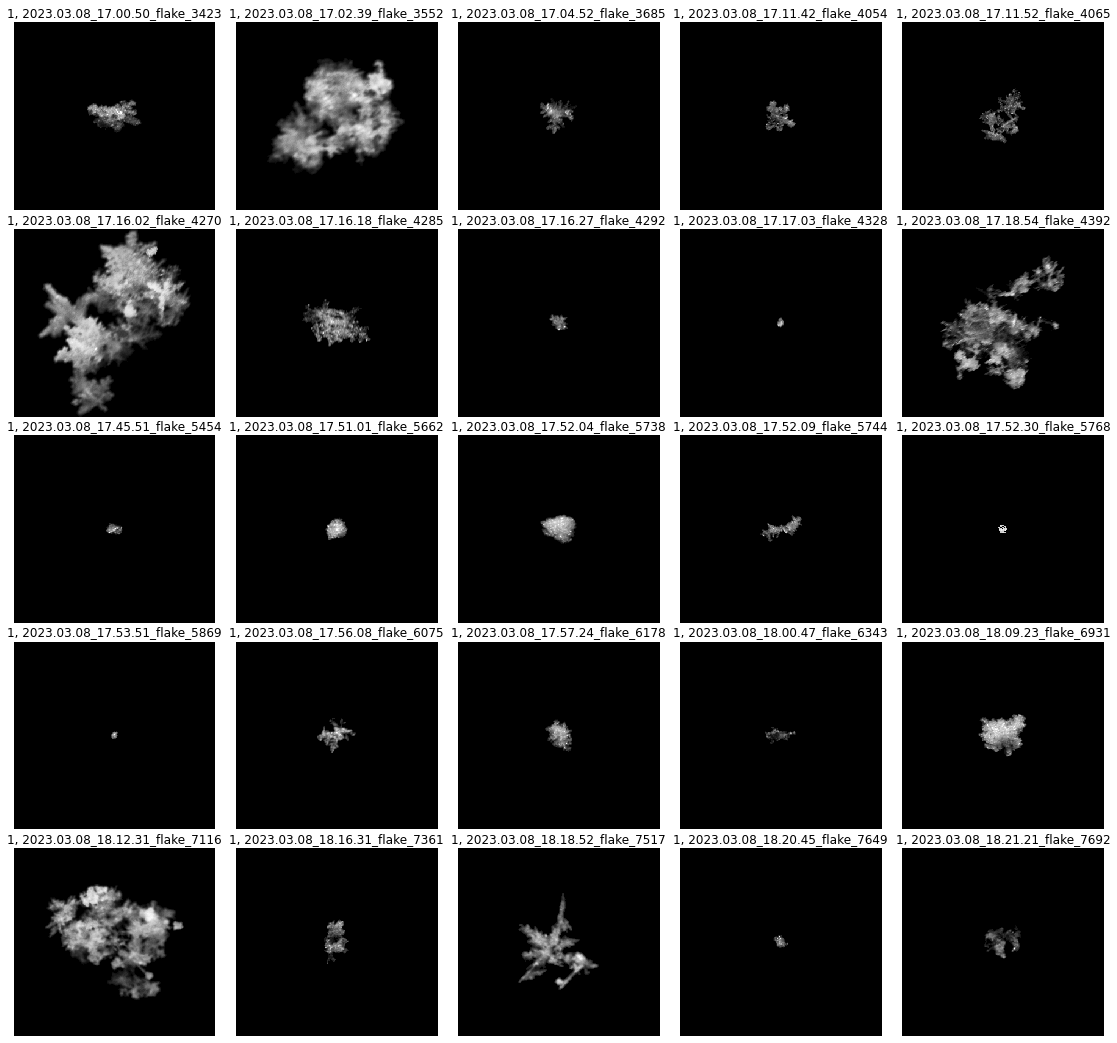

In [62]:
subset_db.plot_flakes(cam_id=1, n_images = 25, col_wrap=5)
# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-08_cam1_3393_3455.png'), format='png', bbox_inches='tight', dpi=300)

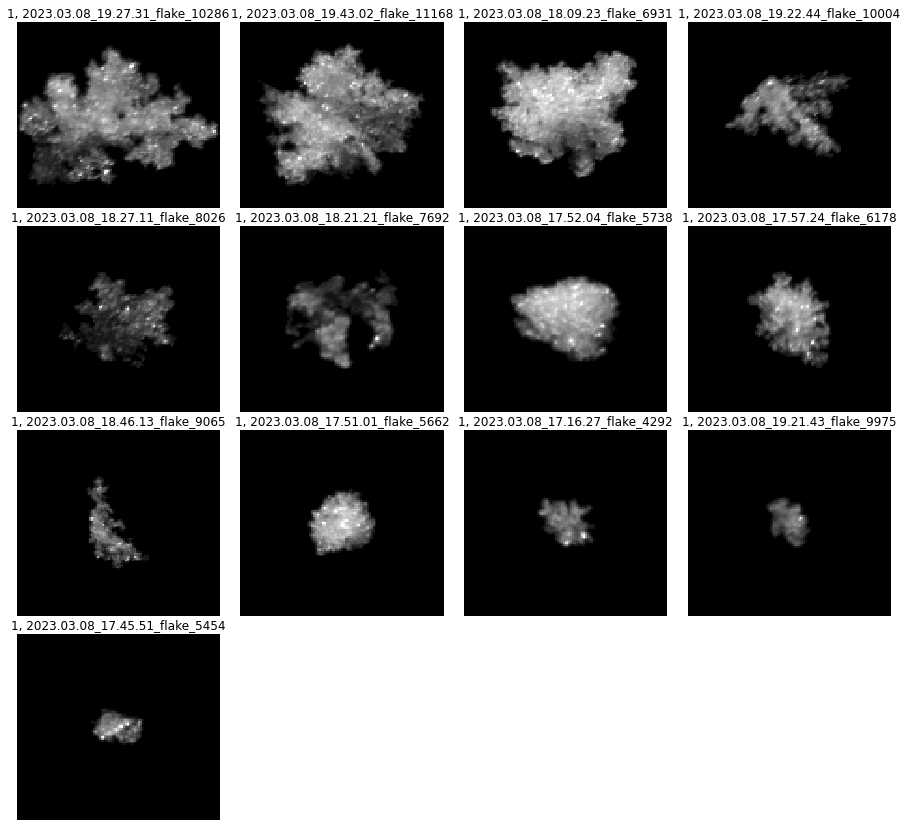

In [63]:
graupel = subset_db.select_snowflake_class('graupel')#.triplet
largeD = graupel.arrange('cam1.Dmax', decreasing=True)   
largeD.plot_flakes(cam_id=1, n_images=13, col_wrap=4)
# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-08_cam1_largest25_graupel.png'), format='png', bbox_inches='tight', dpi=300)

In [64]:
graupel.plot_flakes(cam_id=1, n_images=13, col_wrap=4)

KeyboardInterrupt: 

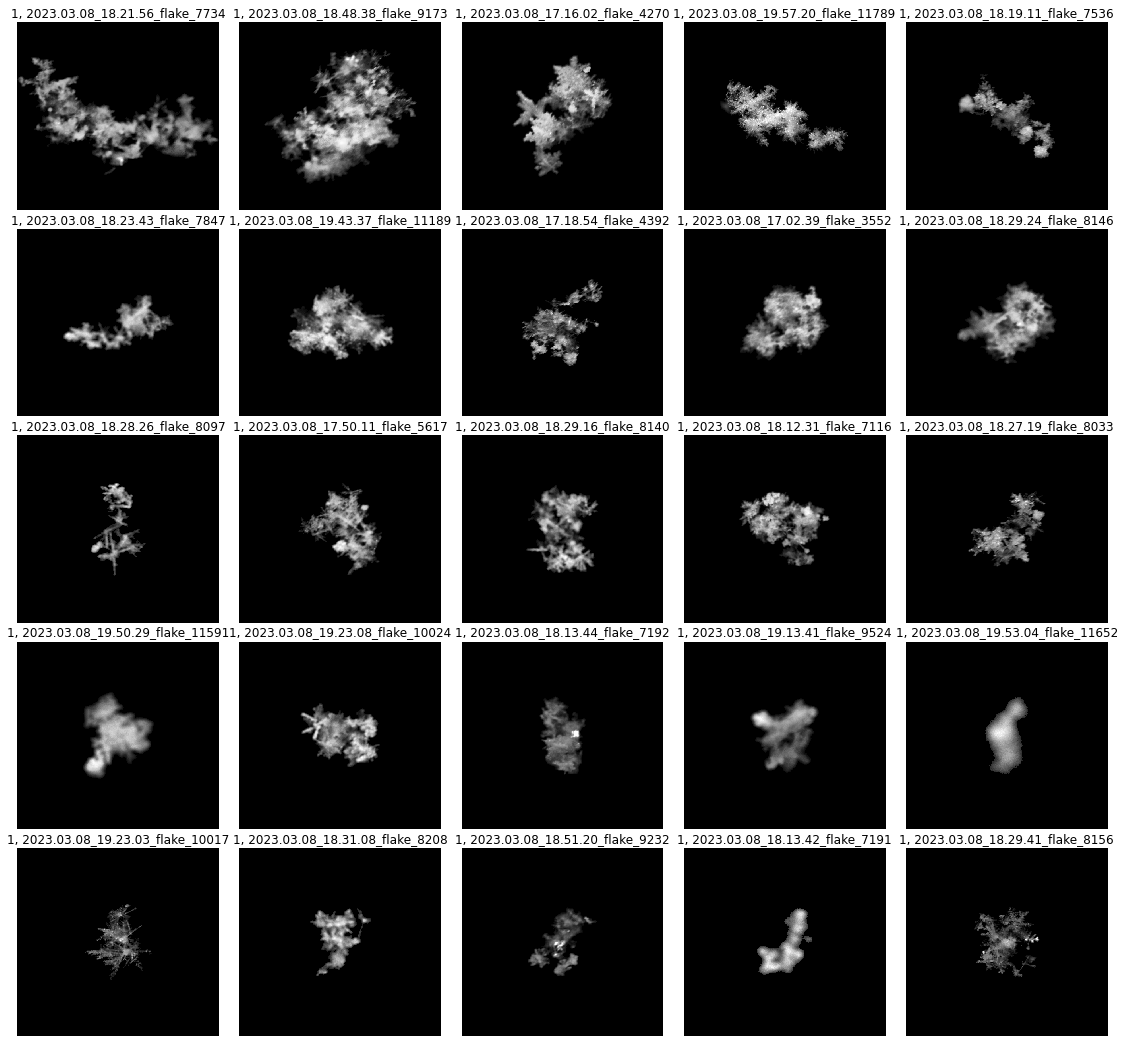

In [ ]:
aggregate = subset_db.select_snowflake_class('aggregate')#.triplet
largeD = aggregate.arrange('cam1.Dmax', decreasing=True)   
largeD.plot_flakes(cam_id=1, n_images=25, col_wrap=5)
# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-08_cam1_largest25_aggregate.png'), format='png', bbox_inches='tight', dpi=300)

Number of flakes: 1462
Filtering on average triplet image quality > 9.5
Number of flakes: 60
Filtering on average triplet hydrometeor classification probabiliy > 0.9
Number of flakes: 13


In [65]:
subset_db.cam1.snowflake_class_name

flake_id
2023.03.08_17.00.50_flake_3423            aggregate
2023.03.08_17.02.39_flake_3552            aggregate
2023.03.08_17.04.52_flake_3685            aggregate
2023.03.08_17.11.42_flake_4054       planar_crystal
2023.03.08_17.11.52_flake_4065            aggregate
2023.03.08_17.16.02_flake_4270            aggregate
2023.03.08_17.16.18_flake_4285            aggregate
2023.03.08_17.16.27_flake_4292              graupel
2023.03.08_17.17.03_flake_4328       small_particle
2023.03.08_17.18.54_flake_4392            aggregate
2023.03.08_17.45.51_flake_5454       small_particle
2023.03.08_17.51.01_flake_5662              graupel
2023.03.08_17.52.04_flake_5738              graupel
2023.03.08_17.52.09_flake_5744       planar_crystal
2023.03.08_17.52.30_flake_5768       small_particle
2023.03.08_17.53.51_flake_5869       small_particle
2023.03.08_17.56.08_flake_6075       planar_crystal
2023.03.08_17.57.24_flake_6178              graupel
2023.03.08_18.00.47_flake_6343            aggregate
202

In [66]:
subset_db.cam2.snowflake_class_name

flake_id
2023.03.08_17.00.50_flake_3423                       aggregate
2023.03.08_17.02.39_flake_3552                       aggregate
2023.03.08_17.04.52_flake_3685                       aggregate
2023.03.08_17.11.42_flake_4054                  planar_crystal
2023.03.08_17.11.52_flake_4065                       aggregate
2023.03.08_17.16.02_flake_4270                       aggregate
2023.03.08_17.16.18_flake_4285                       aggregate
2023.03.08_17.16.27_flake_4292                  small_particle
2023.03.08_17.17.03_flake_4328                  small_particle
2023.03.08_17.18.54_flake_4392                       aggregate
2023.03.08_17.45.51_flake_5454                         graupel
2023.03.08_17.51.01_flake_5662                         graupel
2023.03.08_17.52.04_flake_5738                         graupel
2023.03.08_17.52.09_flake_5744                  planar_crystal
2023.03.08_17.52.30_flake_5768                  small_particle
2023.03.08_17.53.51_flake_5869                